# [모닝학습 시험] 실습 ① 데이터 추출 및 분할


PDF 한 편을 **텍스트 / 표 / 이미지** 세 종류로 분리하는 코드를 **처음부터 직접 작성**합니다.

```
PDF 문서  ──▶  Unstructured Parser  ──▶  텍스트 / 표 / 이미지
```

## 응시 규칙

1. 각 코드 셀에는 **주석만** 있습니다. 주석이 설명하는 코드를 그 아래에 직접 작성하세요.
2. 셀은 위에서부터 순서대로 실행합니다 (`Shift + Enter`).
3. 각 문항의 **채점 기준**을 통과해야 점수를 받습니다.


| 문항 | 내용 | 배점 |
| --- | --- | --- |
| 문제 1 | 환경 검증 | 5 |
| 문제 2 | 라이브러리 임포트 | 5 |
| 문제 3 | 경로 설정 | 10 |
| 문제 4 | PDF 추출 함수 작성 | 20 |
| 문제 5 | 요소 분류 함수 작성 | 15 |
| 문제 6 | 추출 실행 및 분류 | 10 |
| 문제 7 | 요소 타입 집계 | 10 |
| 문제 8 | 추출 이미지 확인 | 10 |
| 문제 9 | 텍스트 분할 | 10 |
| 문제 10 | 결과 저장 | 5 |
| 서술형 | Q1~Q3 | (가산점) |

## 문제 1. 환경 검증 (5점)

> 채점 기준: Poppler, Tesseract, 파이썬 패키지 5종이 모두 `OK`로 출력된다.

In [1]:
# 1-1. shutil, sys 모듈을 임포트하세요.

import shutil
import sys

# 1-2. 현재 Python 버전(sys.version)과 가상환경 경로(sys.prefix)를 출력하세요.

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)

# 1-3. ".venv" 가 sys.prefix 에 포함되어 있는지(가상환경 안에서 실행 중인지) 출력하세요.

print("가상환경 안에서 실행중?", "multimodal" in sys.prefix)
print()

# 1-4. shutil.which()로 OS 패키지 설치 여부를 확인해 "OK" 또는 "✗ 미설치"를 출력하세요.
#      - Poppler   → 실행 파일 이름 "pdftoppm"
#      - Tesseract → 실행 파일 이름 "tesseract"

print("Poppler:", "OK" if shutil.which("pdftoppm") else "✗ 미설치")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치")
print()

# 1-5. 아래 5개 모듈을 반복문으로 __import__ 해 보고,
#      성공하면 "OK", ImportError 가 나면 "✗ 미설치"를 출력하세요.
#      ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]

for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: ✗ 미설치")

Python: 3.11.18
가상환경 경로: c:\Users\jaeyeon\anaconda3\envs\multimodal
가상환경 안에서 실행중? True

Poppler: OK
Tesseract: OK

langchain     : OK
unstructured  : OK
chromadb      : OK
tiktoken      : OK
PIL           : OK


In [2]:
%pip show unstructured-inference

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install "unstructured-inference>=1.6.12,<2.0.0"

  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
   ---------------------------------------- 0.0/7.9 MB ? eta -:--:--
   -- ------------------------------------- 0.5/7.9 MB 5.7 MB/s eta 0:00:02
   ------ --------------------------------- 1.3/7.9 MB 3.7 MB/s eta 0:00:02
   --------- ------------------------------ 1.8/7.9 MB 3.4 MB/s eta 0:00:02
   -------------- ------------------------- 2.9/7.9 MB 3.5 MB/s eta 0:00:02
   ------------------- -------------------- 3.9/7.9 MB 3.9 MB/s eta 0:00:02
   ------------------- -------------------- 3.9/7.9 MB 3.9 MB/s eta 0:00:02
   ------------------- -------------------- 3.9/7.9 MB 3.9 MB/s eta 0:00:02
   --------------------- ------------------ 4.2/7.9 MB 2.8 MB/s eta 0:00:02
   ---------------------- ----------------- 4.5/7.9 MB 2.4 MB/s eta 0:00:02
   ---------------------- ----------------- 4.5/7.9 MB 2.4 MB/s eta 0:00:02
   ---------------------- ----------------- 4.5/7.9 MB 2.4 MB/s eta 0:00:02
   ---------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


## 문제 2. 라이브러리 임포트 (5점)

> 채점 기준: 셀 실행 시 오류 없이 `임포트 완료`가 출력된다.

In [5]:
# 2-1. 표준 라이브러리 os, time, pickle 을 임포트하세요.

import os
import time
import pickle

# 2-2. pathlib 에서 Path 를 임포트하세요.

from pathlib import Path

# 2-3. collections 에서 Counter 를 임포트하세요. (문제 7에서 사용)

from collections import Counter

# 2-4. langchain_text_splitters 에서 CharacterTextSplitter 를 임포트하세요.
#      (긴 텍스트를 일정 크기로 자르는 "작두")

from langchain_text_splitters import CharacterTextSplitter

# 2-5. unstructured.partition.pdf 에서 partition_pdf 를 임포트하세요.
#      (PDF를 텍스트·표·이미지로 나누는 "자동 분리수거 기계")

from unstructured.partition.pdf import partition_pdf

# 2-6. "임포트 완료"를 출력하세요.

print("임포트 완료")

임포트 완료


## 문제 3. 경로 설정 (10점)

> ⚠️ 윈도우에서는 경로에 **한글이나 공백**이 들어가면 뒤에서 오류가 납니다.
>
> 채점 기준: `PDF 존재 여부`가 `True`로 출력된다.

In [6]:
# 3-1. PROJECT_ROOT 를 정의하세요.
#      - 현재 작업 폴더(Path.cwd())의 이름이 "invest" 또는 "practice" 이면 → 상위 폴더(parent)
#      - 그 외에는 → 현재 작업 폴더 그대로

PROJECT_ROOT = Path.cwd().parent

# 3-2. fname 에 본인의 PDF 파일 이름을 문자열로 저장하세요. (예: "invest.pdf")

fname = "invest.pdf"

# 3-3. pdf_dir 에 PDF가 들어 있는 폴더를 Path 객체로 저장하세요. (예: "../invest")

pdf_dir = Path("./data")

# 3-4. pdf_path 를 pdf_dir 와 fname 을 / 연산자로 결합해 만드세요.

pdf_path = pdf_dir / fname

# 3-5. fpath 를 "pdf_dir 문자열 + 경로 구분자(os.sep)" 로 만드세요.
#      (추출 함수에서 path + fname 형태로 이어 붙이기 위함)

fpath = str(pdf_dir) + os.sep

# 3-6. 현재 위치, 프로젝트 루트, PDF 절대 경로(resolve()), PDF 존재 여부(exists())를 출력하세요.

print("현재 위치:", os.getcwd())
print("프로젝트 루트:", PROJECT_ROOT)
print("PDF 절대 경로:", pdf_path.resolve())
print("PDF 존재 여부:", pdf_path.exists())


현재 위치: c:\Users\jaeyeon\studynote\chatbot\langchain-web-chatbot\multimodal\2026-11-05
프로젝트 루트: c:\Users\jaeyeon\studynote\chatbot\langchain-web-chatbot\multimodal
PDF 절대 경로: C:\Users\jaeyeon\studynote\chatbot\langchain-web-chatbot\multimodal\2026-11-05\data\invest.pdf
PDF 존재 여부: True


## 문제 4. PDF 추출 함수 작성 (20점)

아래 옵션표를 참고해 `partition_pdf` 를 호출하는 함수를 작성하세요.

| 옵션 | 값 | 하는 일 |
| --- | --- | --- |
| `strategy` | ? | 레이아웃 분석 모델로 정밀 추출 ("high resolution"의 줄임말) |
| `extract_images_in_pdf` | ? | 그림을 별도 파일로 저장 |
| `infer_table_structure` | ? | 표의 행·열 구조를 추론 |
| `chunking_strategy` | `"by_title"` | 타이틀 기준으로 블록 분할 |
| `max_characters` | `4000` | 블록 최대 글자 수 |
| `new_after_n_chars` | `3800` | 이 글자 수 이후 새 블록 생성 |
| `combine_text_under_n_chars` | `2000` | 이 글자 수 이하 블록은 결합 |
| `image_output_dir_path` | `path + "figures"` | 이미지 저장 폴더 |

> 채점 기준: 오류 없이 `extract_pdf_elements 정의 완료`가 출력되고, 8개 옵션이 모두 올바르다.

In [7]:
# 4-1. extract_pdf_elements(path, fname) 함수를 정의하세요.
#      - docstring: "PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다."

def extract_pdf_elements(path, fname):
    """
    PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다.
    """

# 4-2. 함수 안에서 partition_pdf(...) 의 결과를 return 하세요.
#      - filename 은 path + fname
#      - 나머지 8개 옵션은 위 표를 참고해 모두 지정

    return partition_pdf(
        filename=path + fname,
        strategy="hi_res",
        extract_images_in_pdf=True,
        infer_table_structure=True,
        chunking_strategy="by_title",
        max_characters=4000,
        new_after_n_chars=3800,
        combine_text_under_n_chars=2000,
        extract_image_block_output_dir=str(Path(path) / "figures")
    )

# 4-3. 함수 정의 후 "extract_pdf_elements 정의 완료"를 출력하세요.

print("extract_pdf_elements 정의 완료")

extract_pdf_elements 정의 완료


## 문제 5. 요소 분류 함수 작성 (15점)

추출된 요소를 **텍스트**와 **표** 두 리스트로 나눕니다.

- 요소 타입 문자열에 `unstructured.documents.elements.Table` 이 포함 → 표
- 요소 타입 문자열에 `unstructured.documents.elements.CompositeElement` 가 포함 → 텍스트

> 채점 기준: `(texts, tables)` 순서로 반환하고, 각 요소는 `str()` 로 변환해 저장한다.

In [8]:
# 5-1. categorize_elements(raw_pdf_elements) 함수를 정의하세요.

def categorize_elements(raw_pdf_elements):
    """
    PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다.
    """

# 5-2. 빈 리스트 tables, texts 를 만드세요.

    tables = []
    texts = []

# 5-3. raw_pdf_elements 를 반복하면서 str(type(element)) 를 검사해
#      - Table 이면 tables 에 str(element) 를 추가
#      - CompositeElement 이면 texts 에 str(element) 를 추가

    for element in raw_pdf_elements:
        if "Table" in str(type(element)):
            tables.append(str(element))
        elif "CompositeElement" in str(type(element)):
            texts.append(str(element))

# 5-4. texts, tables 를 (이 순서대로) 반환하세요.

    return texts, tables

# 5-5. 함수 정의 후 "categorize_elements 정의 완료"를 출력하세요.

print("categorize_elements 정의 완료")


categorize_elements 정의 완료


## 문제 6. 추출 실행 및 분류 (10점)

> ⏱️ 추출은 **2~3분** 걸립니다. 대괄호가 `[*]` 이면 실행 중입니다.
>
> 채점 기준: `텍스트 블록 수`가 0보다 크다. (`표 블록 수`는 0이어도 됨 — 표가 이미지로 그려진 PDF일 수 있음)

In [9]:
# 6-1. time.time() 으로 시작 시각을 start 에 저장하세요.

start = time.time()

# 6-2. extract_pdf_elements(fpath, fname) 를 호출해 결과를 raw_pdf_elements 에 저장하세요.

raw_pdf_elements = extract_pdf_elements(fpath, fname)

# 6-3. 소요 시간(소수점 첫째 자리)과 추출된 전체 요소 수(len)를 출력하세요.

end = time.time()
print(f"소요 시간: {end - start:.1f}초")
print(f"추출된 전체 요소 수: {len(raw_pdf_elements)}")

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1
No languages specified, defaulting to English.
Loading weights: 100%|██████████| 367/367 [00:00<00:00, 3219.32it/s]


소요 시간: 224.2초
추출된 전체 요소 수: 19


In [11]:
import inspect

print("fpath:", repr(fpath))
print("저장 예정 위치:", (Path(fpath) / "figures").resolve())
print(inspect.getsource(extract_pdf_elements))

fpath: 'data\\'
저장 예정 위치: C:\Users\user\jaeyeon\studynote\chatbot\langchain-web-chatbot\multimodal\2026-11-05\data\figures
def extract_pdf_elements(path, fname):
    """
    PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다.
    """

# 4-2. 함수 안에서 partition_pdf(...) 의 결과를 return 하세요.
#      - filename 은 path + fname
#      - 나머지 8개 옵션은 위 표를 참고해 모두 지정

    return partition_pdf(
        filename=path + fname,
        strategy="hi_res",
        extract_images_in_pdf=True,
        infer_table_structure=True,
        chunking_strategy="by_title",
        max_characters=4000,
        new_after_n_chars=3800,
        combine_text_under_n_chars=2000,
        extract_image_block_output_dir=str(Path(path) / "figures")
    )



In [10]:
# 6-4. categorize_elements() 로 raw_pdf_elements 를 분류해 texts, tables 에 받으세요.

texts, tables = categorize_elements(raw_pdf_elements)

# 6-5. 텍스트 블록 수와 표 블록 수를 출력하세요.

print(f"텍스트 블록 수: {len(texts)}")
print(f"표 블록 수: {len(tables)}")


텍스트 블록 수: 17
표 블록 수: 2


## 문제 7. 요소 타입 집계 (10점)

> 채점 기준: 요소 타입별 개수가 **많은 순서대로** 출력되고, 아래 답란을 작성한다.

In [11]:
# 7-1. raw_pdf_elements 각 요소의 클래스 이름만 뽑아 Counter 로 집계하세요.
#      힌트: str(type(el)) 은 "<class 'unstructured.documents.elements.Table'>" 형태입니다.
#           "." 으로 split 한 뒤 마지막 조각에서 "'>" 를 strip 하면 "Table" 만 남습니다.

element_counter = Counter([str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements])

# 7-2. most_common() 으로 개수가 많은 순서대로 "타입: N개" 형식으로 출력하세요.

for element_type, count in element_counter.most_common():
    print(f"{element_type}: {count}개")


CompositeElement: 17개
Table: 2개


**문제 7 답란 

- 가장 많이 나온 요소 타입:
- Table이 잡혔는가? 안 잡혔다면 그 이유는:

## 문제 8. 추출 이미지 확인 (10점)

> 채점 기준: 추출된 이미지 개수가 출력되고, 첫 번째 이미지가 노트북 화면에 표시된다.

In [13]:
# 8-1. fpath 아래 "figures" 폴더 경로를 figures_dir 에 Path 객체로 저장하세요.

figures_dir = Path(fpath) / "figures"

# 8-2. figures_dir 가 존재하면
#      - 확장자가 .jpg / .jpeg / .png 인 파일만 골라 정렬한 리스트를 image_files 에 저장
#      - 이미지 개수를 출력
#      - 앞 10개까지 "파일명 (크기 KB)" 형식으로 출력  (크기: f.stat().st_size // 1024)

if figures_dir.exists():
    image_files = sorted([f for f in figures_dir.iterdir() if f.suffix.lower() in [".jpg", ".jpeg", ".png"]])
    print(f"이미지 개수: {len(image_files)}")
    for f in image_files[:10]:
        print(f"{f.name} ({f.stat().st_size // 1024} KB)")

# 8-3. figures_dir 가 없으면 "✗ figures 폴더가 없습니다." 를 출력하세요.

else:
    print("✗ figures 폴더가 없습니다.")


이미지 개수: 6
figure-10-4.jpg (204 KB)
figure-11-5.jpg (86 KB)
figure-13-6.jpg (165 KB)
figure-4-1.jpg (75 KB)
figure-6-2.jpg (66 KB)
figure-9-3.jpg (186 KB)


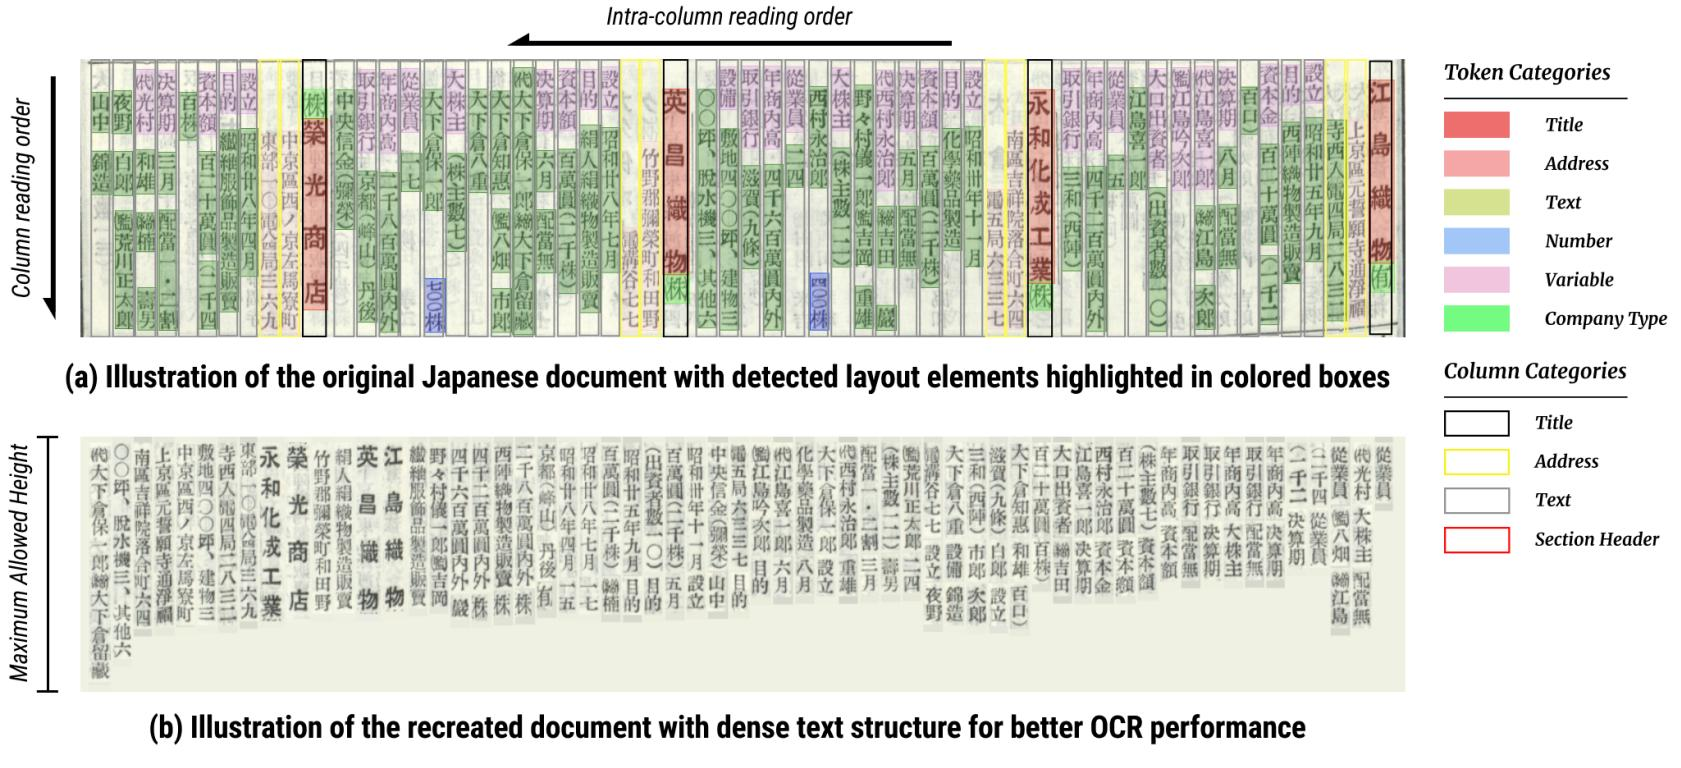

In [14]:
# 8-4. IPython.display 에서 Image, display 를 임포트하세요.

from IPython.display import Image, display

# 8-5. 이미지가 1개 이상 있으면 첫 번째 이미지를 width=500 으로 화면에 표시하세요.
#      없으면 "표시할 이미지가 없습니다." 를 출력하세요.

if image_files:
    display(Image(filename=str(image_files[0]), width=500))
else:
    print("✗ 표시할 이미지가 없습니다.")


## 문제 9. 텍스트 분할 (10점)

추출된 텍스트를 **토큰 기준 2000 단위**로 다시 자르고, 앞뒤를 **200**만큼 겹치게 합니다.

> 채점 기준: `분할 후 블록 수`가 0보다 크고, 원본/분할 결과의 앞 300자가 비교 출력된다.

In [15]:
# 9-1. CharacterTextSplitter.from_tiktoken_encoder() 로 text_splitter 를 만드세요.
#      - chunk_size    : 2000
#      - chunk_overlap : 200

text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=2000,
    chunk_overlap=200
)

# 9-2. texts 리스트를 공백(" ")으로 이어 붙여 joined_texts 에 저장하세요.

joined_texts = " ".join(texts)

# 9-3. text_splitter.split_text() 로 joined_texts 를 분할해 texts_2k_token 에 저장하세요.

texts_2k_token = text_splitter.split_text(joined_texts)

# 9-4. 원본 블록 수, 분할 후 블록 수, 전체 글자 수를 출력하세요.

print(f"원본 블록 수: {len(texts)}")
print(f"분할 후 블록 수: {len(texts_2k_token)}")
print(f"전체 글자 수: {sum(len(text) for text in texts_2k_token)}")


원본 블록 수: 17
분할 후 블록 수: 6
전체 글자 수: 46744


In [16]:
# 9-5. 구분선("=" * 60)과 제목을 함께 사용해
#      texts[0] 의 앞 300자와 texts_2k_token[0] 의 앞 300자를 비교 출력하세요.

print("=" * 60)
print("texts[0] (원본 블록):")
print(texts[0][:300])
print("=" * 60)
print("texts_2k_token[0] (분할 후 블록):")
print(texts_2k_token[0][:300])

texts[0] (원본 블록):
1

2021

2

0

2 n u J 1 2 ] V C . s c [ 2 v 8 4 3 5 1 . 3 0 1 2 :

v

arXiv

i

X

r

a

LayoutParser: A Uniﬁed Toolkit for Deep Learning Based Document Image Analysis

Zejiang Shen! (4), Ruochen Zhang”, Melissa Dell?, Benjamin Charles Germain Lee*, Jacob Carlson?, and Weining Li®

1 Allen Institut
texts_2k_token[0] (분할 후 블록):
1

2021

2

0

2 n u J 1 2 ] V C . s c [ 2 v 8 4 3 5 1 . 3 0 1 2 :

v

arXiv

i

X

r

a

LayoutParser: A Uniﬁed Toolkit for Deep Learning Based Document Image Analysis

Zejiang Shen! (4), Ruochen Zhang”, Melissa Dell?, Benjamin Charles Germain Lee*, Jacob Carlson?, and Weining Li®

1 Allen Institut


In [18]:
print("원본 첫 블록 길이:", len(texts[0]))
print("재분할 첫 블록 길이:", len(texts_2k_token[0]))
print("전체 내용 동일:", texts[0] == texts_2k_token[0])

print("원본 블록 수:", len(texts))
print("재분할 블록 수:", len(texts_2k_token))

원본 첫 블록 길이: 2167
재분할 첫 블록 길이: 8656
전체 내용 동일: False
원본 블록 수: 17
재분할 블록 수: 6


## 문제 10. 결과 저장 (5점)

추출에 시간이 오래 걸리므로 다음 교시에서 바로 불러 쓸 수 있게 저장합니다.

> 채점 기준: `data/processed/extracted.pkl` 파일이 생성된다.

In [17]:
# 10-1. PROJECT_ROOT / "data" / "processed" 경로를 output_dir 에 저장하세요.

output_dir = Path(PROJECT_ROOT) / "data" / "processed"

# 10-2. output_dir 폴더를 생성하세요. (상위 폴더까지 생성, 이미 있어도 오류 없이)

output_dir.mkdir(parents=True, exist_ok=True)

# 10-3. output_dir / "extracted.pkl" 파일을 바이너리 쓰기 모드("wb")로 열고,
#       {"texts": ..., "tables": ..., "texts_2k_token": ...} 딕셔너리를 pickle.dump 하세요.

with open(output_dir / "extracted.pkl", "wb") as f:
    pickle.dump({"texts": texts, "tables": tables, "texts_2k_token": texts_2k_token}, f)

# 10-4. "저장 완료:" 와 함께 저장 경로를 출력하세요.

print(f"저장 완료: {output_dir / 'extracted.pkl'}")


저장 완료: c:\Users\jaeyeon\studynote\chatbot\langchain-web-chatbot\multimodal\data\processed\extracted.pkl



## ✅ 제출 전 최종 점검

- [ ] `figures/` 폴더에 이미지 파일이 있다
- [ ] `len(texts)`와 `len(texts_2k_token)`이 둘 다 0보다 크다
- [ ] 추출된 그림을 **눈으로** 확인했다
- [ ] `data/processed/extracted.pkl` 파일이 생성되었다
- [ ] 문제 1~10 을 모두 작성했다